In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/apple.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/cake.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/cat.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/circle.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/clock.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/diamond.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/fish.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/flower.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/sun.npy
/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/tree.npy


# Doodle Search Engine with Quick Draw!

In [2]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings
import keras
from PIL import Image

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.utils import load_img, img_to_array

import tensorflow as tf
from keras.applications.mobilenet_v2 import preprocess_input

from tqdm import tqdm


warnings.filterwarnings("ignore")

In [3]:
keras.utils.set_random_seed(42)

## Loading the data

In [4]:
path = "/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/"   
files_path = glob.glob(path + "*.npy")
files_path

['/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/apple.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/cake.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/cat.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/circle.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/clock.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/diamond.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/fish.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/flower.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/sun.npy',
 '/kaggle/input/datasets/rawanalmahoozi/drawings-doodle/tree.npy']

In [5]:
img = np.load(files_path[0], mmap_mode="r")
img

memmap([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

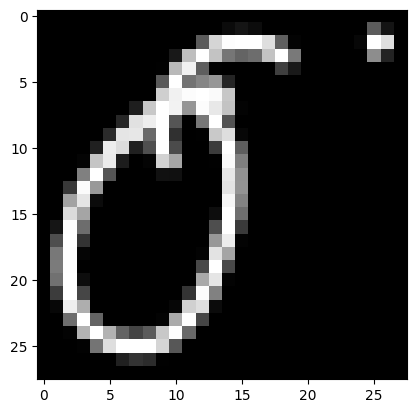

In [6]:
plt.imshow(img[0].reshape(28, 28), cmap="gray")

## Sampling the data

In [7]:
files_path = sorted(files_path)
categories = [os.path.basename(f).replace(".npy", "") for f in files_path]
categories

['apple',
 'cake',
 'cat',
 'circle',
 'clock',
 'diamond',
 'fish',
 'flower',
 'sun',
 'tree']

In [8]:
# sample the data, so that we have 450 for gallary, and 50 for query in each category
rng = np.random.default_rng(42)

rng = np.random.default_rng(42)

gallery_x = []
gallery_y = []
query_x = []
query_y = []

for category in categories:

    file_path = os.path.join(path, category + ".npy")
    images = np.load(file_path, mmap_mode="r")

    random_indices = rng.choice(len(images), size=500, replace=False)
    selected_images = images[random_indices]

    gallery.append(selected_images[:450])
    gallery_label.append([category] * 450)

    query.append(selected_images[450:])
    query_label.append([category] * 50)

gallery = np.concatenate(gallery) #so they all be in one big aray
gallery_label = np.concatenate(gallery_label)

query = np.concatenate(query)
query_label = np.concatenate(query_label)

100%|██████████| 10/10 [02:15<00:00, 13.57s/it]


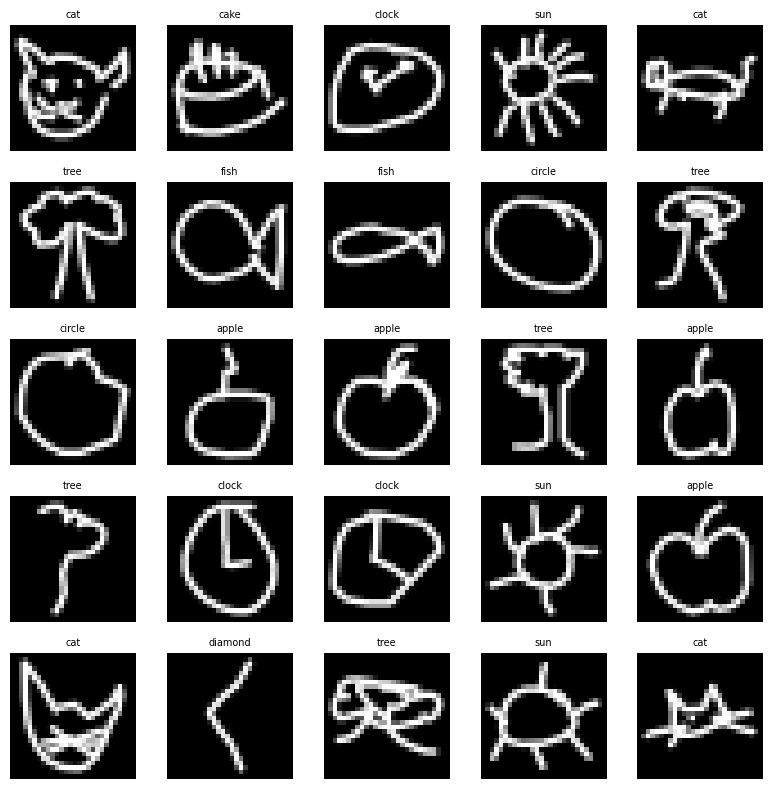

In [9]:
#view random 25 doodles
pick = np.random.choice(len(gallery_x), 25, replace=False)

plt.figure(figsize=(8, 8))
for i, p in enumerate(pick):
    plt.subplot(5, 5, i + 1)
    plt.imshow(gallery_x[p].reshape(28, 28), cmap="gray")
    plt.title(categories[gallery_y[p]], fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Model for feature extraction

In [10]:
backbone = MobileNetV2(
                        weights="imagenet",
                        include_top=False,
                        pooling="avg"
                      )


I0000 00:00:1793464434.584001      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793464434.587318      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [11]:
backbone.trainable = False  
backbone.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, None,      │        864 │ input_layer[0][0] │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, None,      │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, None,      │          0 │ bn_Conv1[0][0]    │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, None,      │          0 │ expanded_conv_de… │
│ (ReLU)              │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │        512 │ expanded_conv_de… │
│ (Conv2D)            │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, None,      │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ None, 16)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, None,      │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, None,      │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, None,      │          0 │ block_1_expand_B… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, None,      │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, None,      │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, None,      │          0 │ block_1_depthwis… │
│ (ReLU)              │ None, 96)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, None,      │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

## Preprocessing & embedding one doodle 'To check everything is okay'

In [ ]:
# According to the documentation, input should be:
#- Exactly 3 colour channels (RGB).
#- Height must be at least 32 pixels.
#- Width must be at least 32 pixels.
#- Height and width can be different sizes.

In [ ]:
print(backbone.input_shape)

In [ ]:
print(gallery_x.shape)
print(query_x.shape)

In [12]:
def preprocess_img(doodle):
    img = np.array(doodle).reshape(28, 28, 1).astype("float32") #change the 1D seeting
    img = tf.image.resize(img, (160, 160)).numpy()
    img_array = np.repeat(img, 3, axis=-1)
    preprocessed_img = preprocess_input(img_array)
    return preprocessed_img

In [13]:
preprocessed_img = preprocess_img(img[0])
preprocessed_img.shape

(160, 160, 3)

In [14]:
def extract_embedding(doodle):
    preprocessed_img = preprocess_img(doodle)
    img = np.expand_dims(preprocessed_img, axis=0)
    embedding = backbone.predict(img, verbose=0) #predict to find the embedding for each image
    return embedding

In [15]:
extract_embedding(img[0]).shape

2026-10-31 16:34:07.108239: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 16:34:07.257473: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 16:34:07.391072: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793464448.665036     179 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


(1, 1280)

## Building the index

In [16]:
from tqdm import tqdm

# Extract features for every doodle in the gallery
feature_list = []

for doodle in tqdm(gallery_x):
    feature_list.append(extract_embedding(doodle))

# Convert to a numpy array
feature_list = np.squeeze(np.array(feature_list))

100%|██████████| 4500/4500 [06:15<00:00, 11.97it/s]


In [17]:
feature_list.shape

(4500, 1280)

In [18]:
#now we do the same but for the query set
query_features = []

for doodle in tqdm(query_x):
    query_features.append(extract_embedding(doodle))

query_features = np.squeeze(np.array(query_features))

100%|██████████| 500/500 [00:42<00:00, 11.78it/s]


In [19]:
query_features.shape

(500, 1280)

## Searching with cosine similarity

In [20]:
#nearest neighbor (25, cosine)
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=25, algorithm='brute', metric='cosine')
neighbors.fit(feature_list)

NearestNeighbors(algorithm='brute', metric='cosine', n_neighbors=25)

In [21]:
distances, indices = neighbors.kneighbors(query_features)

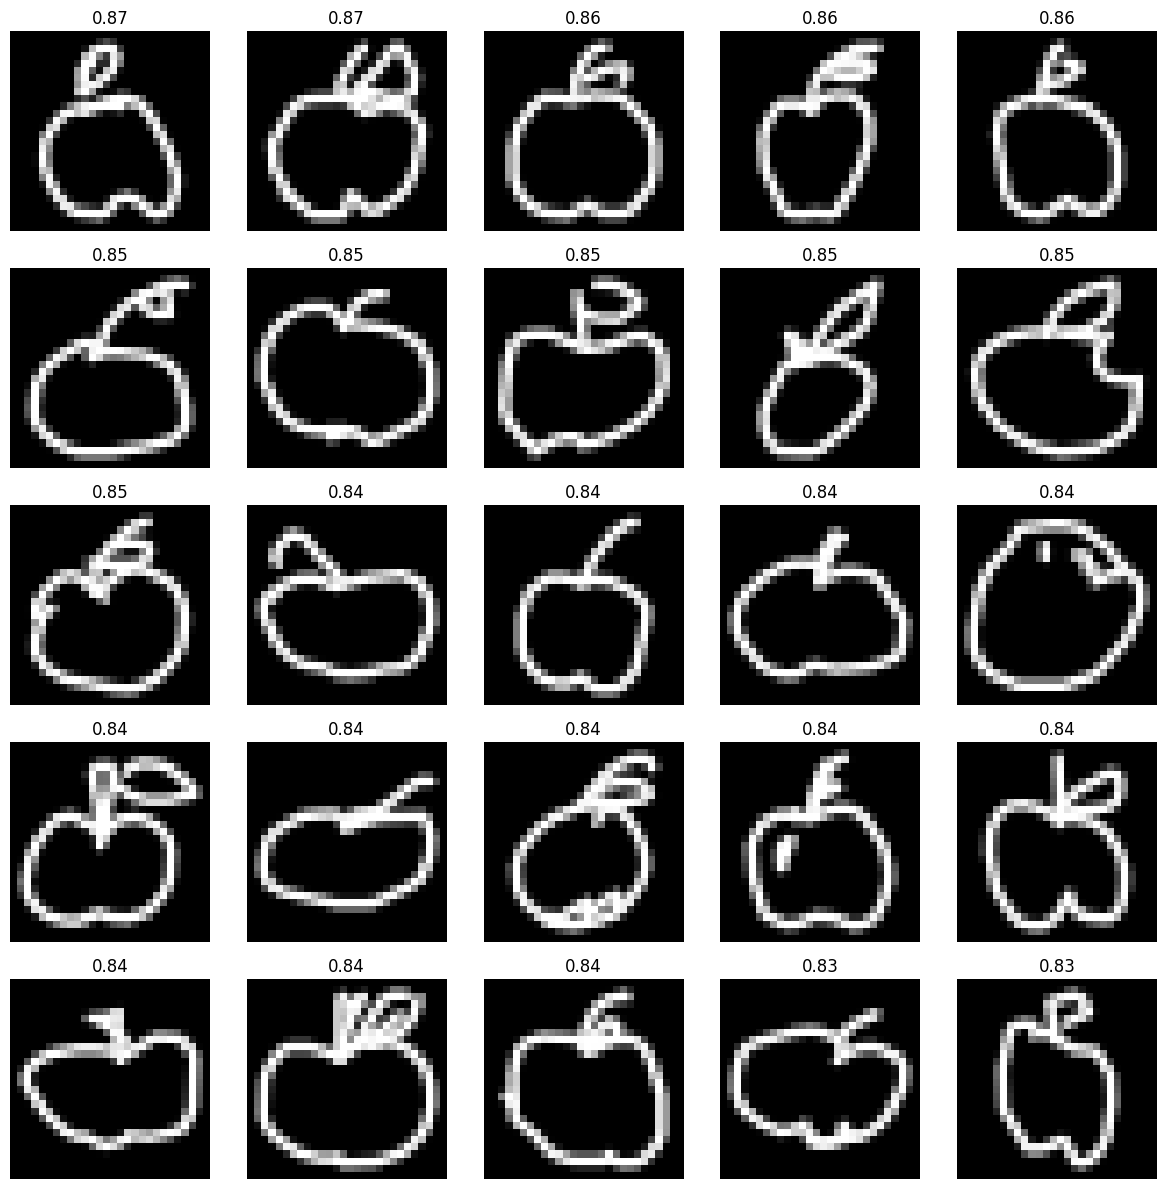

In [22]:
plt.figure(figsize=(12, 12))

for i, idx in enumerate(indices[0]):
    plt.subplot(5, 5, i + 1)
    plt.imshow(gallery_x[idx].reshape(28, 28), cmap='gray')

    similarity = 1 - distances[0][i]
    plt.title(f"{similarity:.2f}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [23]:
#search 
from sklearn.preprocessing import normalize
def search_similar(doodle):
    #processing
    embedding = extract_embedding(doodle) #extract
    embedding = normalize(embedding, norm='l2')
    #find 25 neighbors
    distances, indices = neighbors.kneighbors(embedding)
    #convert dis to sim score
    similarities = 1 - distances[0]
    return indices[0], similarities

In [24]:
matched_indices, scores = search_similar(query_x[0])

In [25]:
#displaying resluts 
def display_results(indices, scores):
    plt.figure(figsize=(12, 12))
    for i, idx in enumerate(indices):
        plt.subplot(5, 5, i + 1)
        plt.imshow(gallery_x[idx].reshape(28, 28), cmap='gray')
        plt.title(f"Similarity: {scores[i]:.2f}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

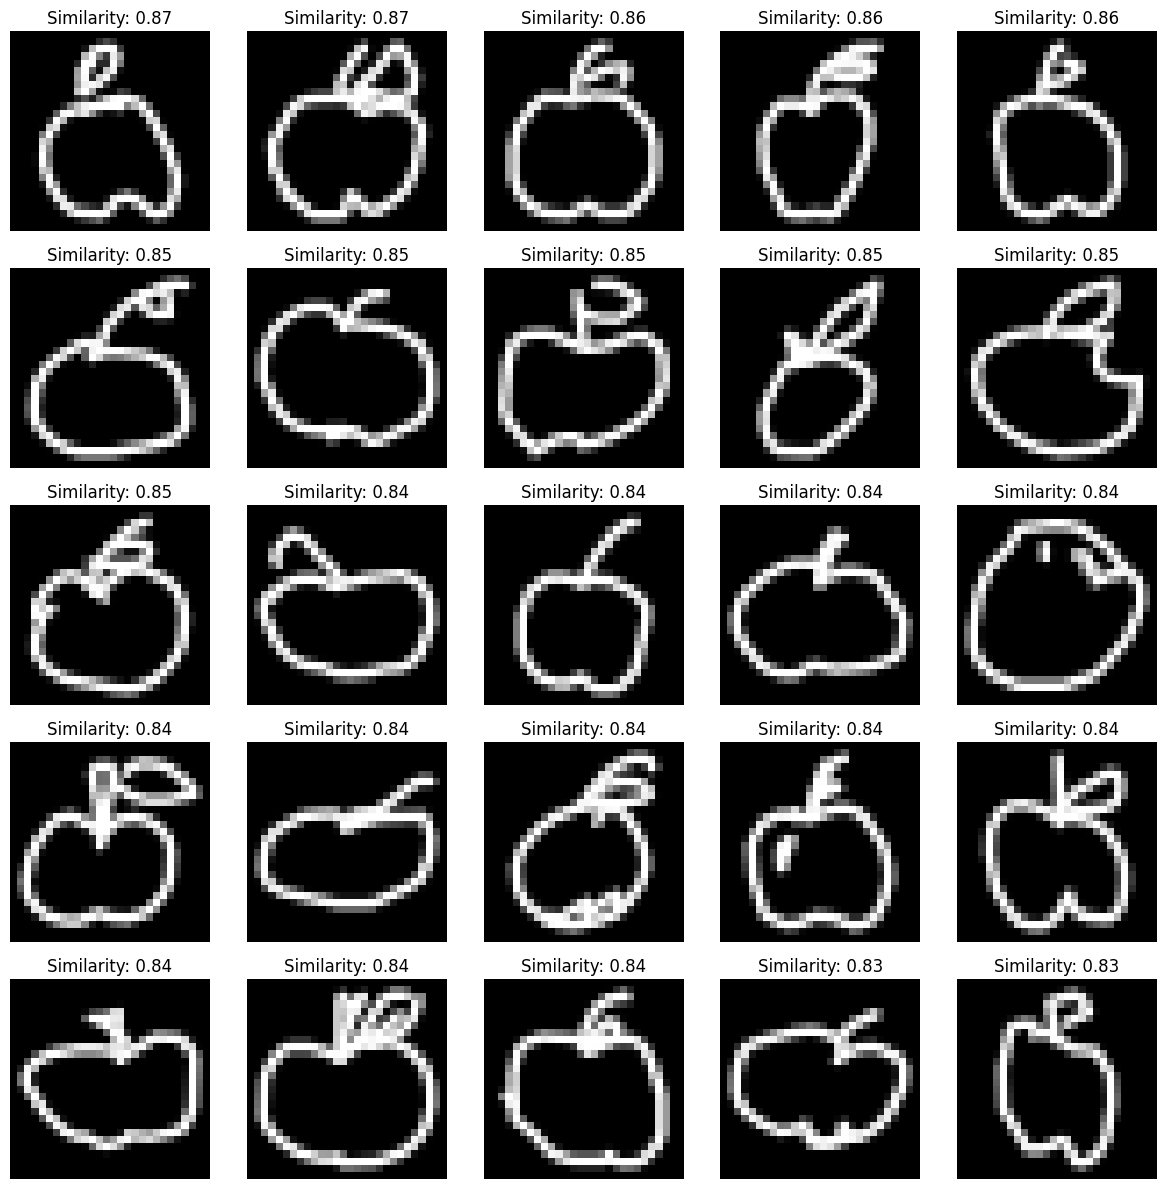

In [26]:
matched_indices, scores = search_similar(query_x[0])

display_results(matched_indices, scores)

In [33]:
#save for streamlit app
np.savez_compressed(
    "/kaggle/working/doodle_gallery.npz",
    images=gallery_x,
    embeddings=feature_list.astype("float32")
)